# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [4]:
# Add code here 🔧
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Load the dataset from GitHub (corrected directory casing to 'DataSets')
url = 'https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/hotels.csv'
df = pd.read_csv(url)

df.head()
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,7069.000000,1011.000000,9404.000000,9404.000000,9404.000000,9404.000000
mean,0.248299,79.326244,2015.156104,37.026584,15.515313,1.155040,3.078690,1.864738,0.095279,0.015419,0.077839,0.419715,0.290196,0.238622,200.990946,219.550940,1.019034,86.843614,0.144938,0.613143
std,0.432049,87.584146,0.443661,11.083421,9.025545,1.124304,2.379227,1.198565,0.393858,0.125781,0.267933,2.726546,1.352679,0.630041,80.330753,104.296474,10.137928,53.759940,0.353264,0.835930
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,9.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,8.000000,2015.000000,31.000000,7.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,156.000000,135.000000,0.000000,45.000000,0.000000,0.000000
50%,0.000000,48.000000,2015.000000,38.000000,16.000000,1.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,240.000000,223.000000,0.000000,71.550000,0.000000,0.000000
75%,0.000000,118.000000,2015.000000,45.000000,23.000000,2.000000,5.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,241.000000,286.000000,0.000000,120.600000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,13.000000,33.000000,55.000000,10.000000,2.000000,1.000000,26.000000,26.000000,17.000000,468.000000,511.000000,122.000000,508.000000,2.000000,5.000000


### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1. Lead time stands out because its maximum is 737 days, which is much higher than its mean of about 79 days, suggesting possible outliers.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [ ]:
# Add code here 🔧


In [9]:
# Select features
features = ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights']

# 1. Drop missing values in the selected columns
df_prepared = df.dropna(subset=features).copy()

# 2. Correct datatypes to integer
for col in features:
    df_prepared[col] = df_prepared[col].astype(int)

# 3. Remove outliers using IQR method
for col in features:
    Q1 = df_prepared[col].quantile(0.25)
    Q3 = df_prepared[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df_prepared = df_prepared[(df_prepared[col] >= lower_bound) & (df_prepared[col] <= upper_bound)]

# 4. Remove duplicate rows based on the selected features
df_prepared = df_prepared.drop_duplicates(subset=features)

# 5. Standardize variables with values over 100 (lead_time)
scaler = StandardScaler()
# Fit and transform lead_time, replacing it in the prepared dataframe
df_prepared['lead_time'] = scaler.fit_transform(df_prepared[['lead_time']])

# Display the prepared dataset characteristics
print(f"Prepared dataset shape: {df_prepared.shape}")
df_prepared[features].head()

Prepared dataset shape: (2411, 32)


,lead_time,stays_in_weekend_nights,stays_in_week_nights
2,-1.220330,0,1
3,-1.131781,0,1
4,-1.117023,0,2
6,-1.323637,0,2
7,-1.190814,0,2


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. I selected lead_time, stays_in_weekend_nights, and stays_in_week_nights because they describe when guests book and how long they stay. These behaviors can help the hotel identify different types of guests.

2. I expect to find groups such as short-stay guests who book close to arrival, guests who book far in advance, and longer-stay guests who spend several weekday or weekend nights at the hotel.


## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

In [ ]:
# Add code here 🔧

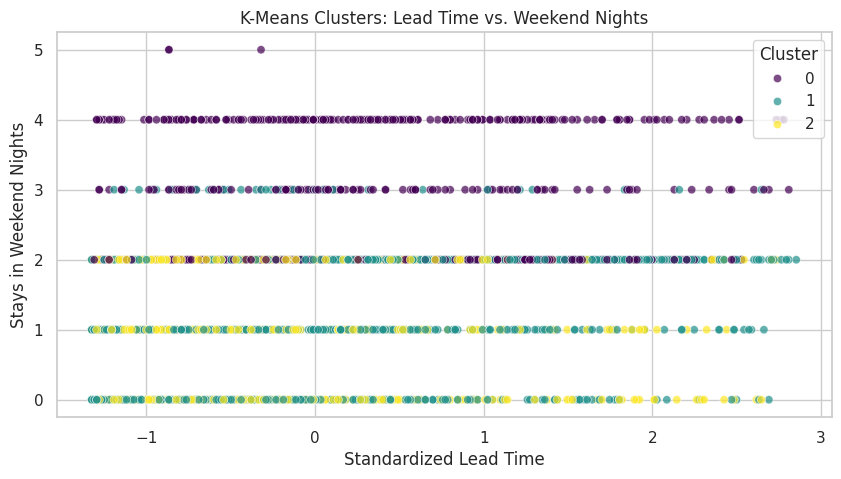

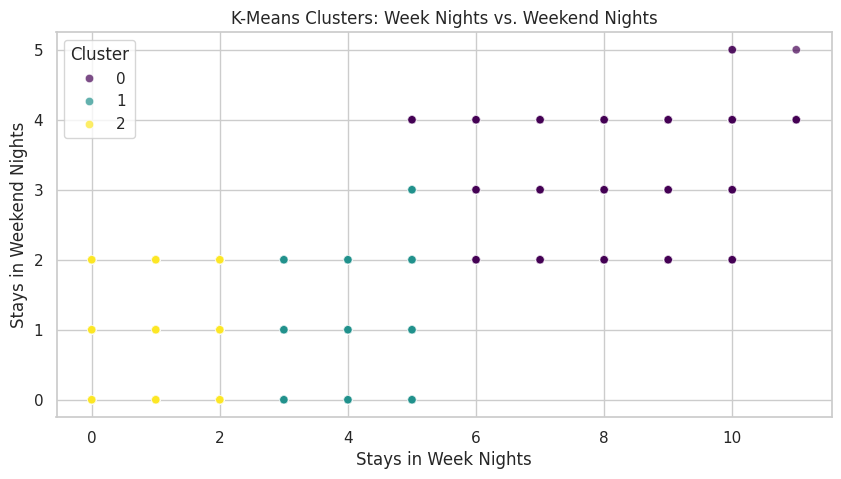

=== Cluster Summary Averages ===
                lead_time  stays_in_weekend_nights  stays_in_week_nights
cluster_kmeans                                                          
0                0.315222                 2.987633              7.510601
1                0.038702                 1.258834              4.033569
2               -0.311679                 0.963534              1.279102


In [10]:
# 1. Initialize and fit KMeans with k=3
k_value = 3
kmeans = KMeans(n_clusters=k_value, random_state=42)
df_prepared['cluster_kmeans'] = kmeans.fit_predict(df_prepared[features])

# Set seaborn style for clean plotting
sns.set_theme(style="whitegrid")

# 2. First visualization: Lead Time vs Stays in Weekend Nights
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df_prepared,
    x='lead_time',
    y='stays_in_weekend_nights',
    hue='cluster_kmeans',
    palette='viridis',
    alpha=0.7
)
plt.title('K-Means Clusters: Lead Time vs. Weekend Nights')
plt.xlabel('Standardized Lead Time')
plt.ylabel('Stays in Weekend Nights')
plt.legend(title='Cluster')
plt.show()

# 3. Second visualization: Stays in Week Nights vs Stays in Weekend Nights
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df_prepared,
    x='stays_in_week_nights',
    y='stays_in_weekend_nights',
    hue='cluster_kmeans',
    palette='viridis',
    alpha=0.7
)
plt.title('K-Means Clusters: Week Nights vs. Weekend Nights')
plt.xlabel('Stays in Week Nights')
plt.ylabel('Stays in Weekend Nights')
plt.legend(title='Cluster')
plt.show()

# 4. Summary table of the averages of each variable per cluster
summary_table = df_prepared.groupby('cluster_kmeans')[features].mean()
print("=== Cluster Summary Averages ===")
print(summary_table)

### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. I chose k = 3 because the data may naturally separate into three useful guest groups: short-stay/last-minute guests, guests who book farther in advance, and longer-stay guests

2. Cluster 0 appears to contain the longest-stay guests, with the highest number of weekday nights and usually several weekend nights. Cluster 1 represents medium-length stays, with around three to five weekday nights and fewer weekend nights. Cluster 2 contains short-stay guests, who usually have two or fewer weekday nights and few or no weekend nights.


## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

In [ ]:
# Add your code here

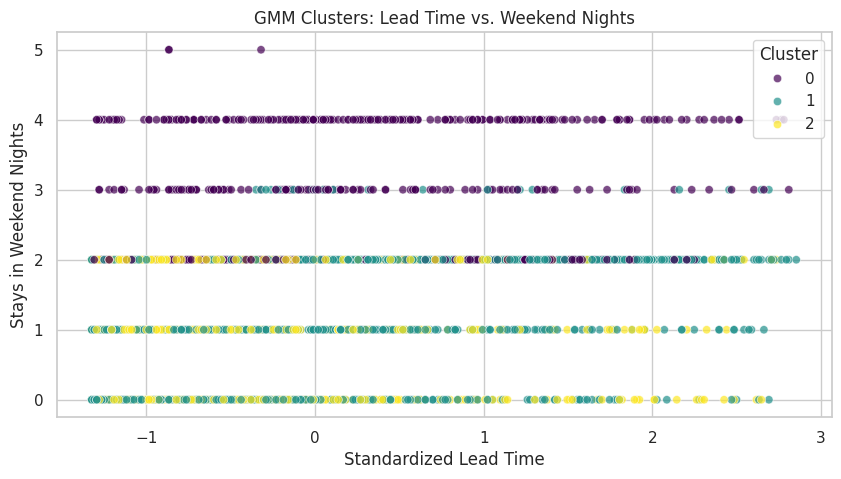

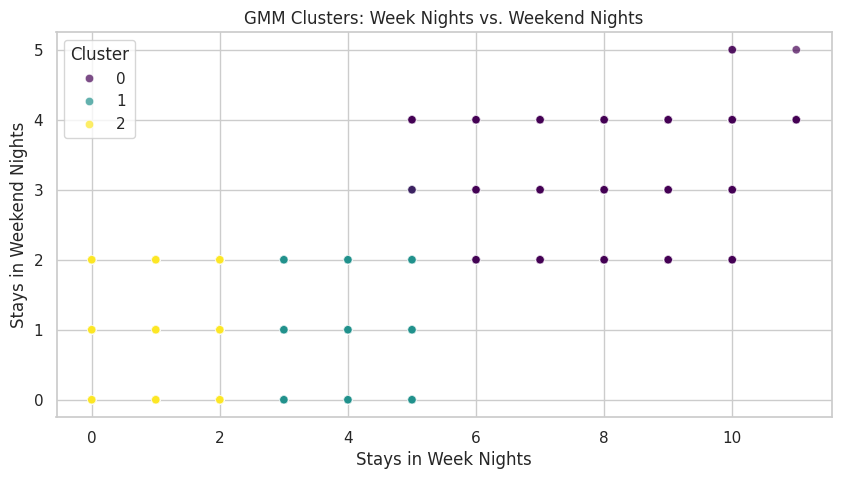

=== GMM Cluster Summary Averages ===
             lead_time  stays_in_weekend_nights  stays_in_week_nights
cluster_gmm                                                          
0             0.202977                 3.098456              7.627413
1             0.099224                 1.280508              4.123729
2            -0.311679                 0.963534              1.279102


In [11]:
# 1. Initialize and fit Gaussian Mixture Model (GMM) with 3 clusters
gmm = GaussianMixture(n_components=3, random_state=42)
gmm.fit(df_prepared[features])

# Predict probabilities (soft clusters)
soft_probs = gmm.predict_proba(df_prepared[features])

# Assign the most probable cluster label to each guest
df_prepared['cluster_gmm'] = gmm.predict(df_prepared[features])

# Set seaborn style for clean plotting
sns.set_theme(style="whitegrid")

# 2. First visualization: Lead Time vs Stays in Weekend Nights
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df_prepared,
    x='lead_time',
    y='stays_in_weekend_nights',
    hue='cluster_gmm',
    palette='viridis',
    alpha=0.7
)
plt.title('GMM Clusters: Lead Time vs. Weekend Nights')
plt.xlabel('Standardized Lead Time')
plt.ylabel('Stays in Weekend Nights')
plt.legend(title='Cluster')
plt.show()

# 3. Second visualization: Stays in Week Nights vs Stays in Weekend Nights
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df_prepared,
    x='stays_in_week_nights',
    y='stays_in_weekend_nights',
    hue='cluster_gmm',
    palette='viridis',
    alpha=0.7
)
plt.title('GMM Clusters: Week Nights vs. Weekend Nights')
plt.xlabel('Stays in Week Nights')
plt.ylabel('Stays in Weekend Nights')
plt.legend(title='Cluster')
plt.show()

# 4. Summary table of the averages of each variable per cluster
gmm_summary_table = df_prepared.groupby('cluster_gmm')[features].mean()
print("=== GMM Cluster Summary Averages ===")
print(gmm_summary_table)

### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1. The GMM results were very similar to KMeans because both identified short-, medium-, and long-stay guest groups. However, GMM also provides probabilities, so it can show when a guest may fit more than one segment instead of forcing them into only one.

2. GMM would be especially useful for questions involving uncertain or borderline guests, such as which customers should receive a targeted offer. The hotel could use the probability that a guest belongs to a long-stay or short-stay segment when planning promotions, staffing, or room availability


## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [ ]:
# Add code here 🔧

In [12]:
# 1. K-Means Evaluation Metrics
kmeans_wcss = kmeans.inertia_
kmeans_silhouette = silhouette_score(df_prepared[features], df_prepared['cluster_kmeans'])
kmeans_db = davies_bouldin_score(df_prepared[features], df_prepared['cluster_kmeans'])

# 2. GMM Evaluation Metrics
# For GMM, WCSS can be calculated as the sum of squared distances to the assigned cluster centers
gmm_centers = gmm.means_
gmm_labels = df_prepared['cluster_gmm']
# Fixed the NotImplementedError by replacing .iloc with direct boolean indexing
gmm_wcss = np.sum([np.sum((df_prepared[features][gmm_labels == i] - gmm_centers[i])**2) for i in range(gmm.n_components)])

gmm_silhouette = silhouette_score(df_prepared[features], df_prepared['cluster_gmm'])
gmm_db = davies_bouldin_score(df_prepared[features], df_prepared['cluster_gmm'])

# 3. Print the results in a formatted output
print("=== Model Evaluation Metrics ===\n")
print(f"{'Metric':<25} | {'K-Means':<12} | {'GMM':<12}")
print("-" * 58)
print(f"{'WCSS (Inertia)':<25} | {kmeans_wcss:<12.4f} | {gmm_wcss:<12.4f}")
print(f"{'Silhouette Score':<25} | {kmeans_silhouette:<12.4f} | {gmm_silhouette:<12.4f}")
print(f"{'Davies-Bouldin Index':<25} | {kmeans_db:<12.4f} | {gmm_db:<12.4f}")

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:84: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)
/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:84: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)
/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:84: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs

=== Model Evaluation Metrics ===

Metric                    | K-Means      | GMM         
----------------------------------------------------------
WCSS (Inertia)            | 6678.5467    | 6938.1065   
Silhouette Score          | 0.3522       | 0.3493      
Davies-Bouldin Index      | 0.9731       | 0.9603      


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. KMeans performed slightly better overall because it had a lower WCSS and a higher silhouette score than GMM. GMM had a slightly better Davies-Bouldin Index, but the difference was very small

5.3. I would recommend KMeans because its clusters performed slightly better overall and are easier for a business analyst to explain and use.


## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [ ]:
# Add code here 🔧


=== Sorted Cluster Characteristics (Ordered by Total Stay Length) ===
                lead_time  stays_in_weekend_nights  stays_in_week_nights  \
cluster_kmeans                                                             
2                  -0.312                    0.964                 1.279   
1                   0.039                    1.259                 4.034   
0                   0.315                    2.988                 7.511   

                total_of_special_requests  total_nights  
cluster_kmeans                                           
2                                   0.818         2.243  
1                                   0.812         5.292  
0                                   0.742        10.498  


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1. The segments represent short-stay guests who book relatively close to arrival, medium-stay guests, and long-stay guests who tend to book farther in advance. The number of special requests is very similar across the groups, so stay length is the main difference.

2. The hotel could offer short-stay guests discounted extra-night or weekend packages to encourage longer visits. Medium- and long-stay guests could receive loyalty rewards, extended-stay rates, or packages that include amenities and local activities. Most hotels already offer special rewards and points for using their services, so this also shifts demand.


## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. The most challenging thing about unsupervised learning was choosing which freatures and the number of clusters that provide meaningful groups because there are no labels to compare against.

2. I would use clustering when I want to discover hidden trends and patterns that occur naturally, but don't have an specific variable outcome to predict.

3. Cluserting helps turn a large group of customers into a few identifiable customer types. This helps us tailor actions to different guests.

4. This relates to my customized learning outcome because it shows how data analysis can be used to support business decisions. I learned how to prepare data, identify meaningful patterns, and explain results in a way that is useful to managers.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [15]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"

[NbConvertApp] Converting notebook assignment_09_clustering.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 4 image(s).
[NbConvertApp] Writing 721943 bytes to assignment_09_clustering.html
